In [2]:
import numpy as np
import pandas as pd
from os import listdir, path, makedirs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

In [2]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path):
    for name in names:
        file_path = os.path.join(base_path, name, "quantify_genome/output_unique_biotype.csv")
        df = pd.read_csv(file_path, sep=',')
        df_dict[name] = df[df['gene_biotype'].notna()]


def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='gene_biotype', how='left').fillna(0)
    result_df = result_df.rename(columns={'unique_seq_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['gene_biotype'] for name in names]).unique()
    result_df = pd.DataFrame({'gene_biotype': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)

In [3]:
# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
# read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


#df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total_with_match, base_path)


# filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_gene_biotype_count.csv")


DataFrame SRR18078869 has 8 lines.
DataFrame SRR18078868 has 8 lines.
DataFrame SRR18078867 has 9 lines.
DataFrame SRR18078872 has 8 lines.
DataFrame SRR18078871 has 8 lines.
DataFrame SRR18078870 has 8 lines.
{'SRR18078869':      gene_biotype  unique_seq_count
0     RNase_P_RNA               259
1         SRP_RNA               414
3           ncRNA               147
4  protein_coding            116926
5      pseudogene               323
6            rRNA            680468
7            tRNA            125427
8           tmRNA               606, 'SRR18078868':      gene_biotype  unique_seq_count
0     RNase_P_RNA               357
1         SRP_RNA               469
3           ncRNA                49
4  protein_coding             11288
5      pseudogene                72
6            rRNA            424081
7            tRNA            123315
8           tmRNA               772, 'SRR18078867':      gene_biotype  unique_seq_count
0     RNase_P_RNA              1530
1         SRP_RNA     

aaa
         index    0    1    2       3     4       5       6     7   8
0  SRR18078869  280  447  158  126465   349  735983  135659   655   0
1  SRR18078868  637  836   87   20142   128  756742  220047  1377   0
2  SRR18078867  519  509  280   23151   247  831723  141669  1832  65
3  SRR18078872  107    9    1   70983   539  914070   14272    16   0
4  SRR18078871  249   35    2  164557  1225  820460   13412    57   0
5  SRR18078870   51   21    7  133009   964  857827    8094    23   0
[[   280    447    158 126465    349 735983 135659    655      0]
 [   637    836     87  20142    128 756742 220047   1377      0]
 [   519    509    280  23151    247 831723 141669   1832     65]
 [   107      9      1  70983    539 914070  14272     16      0]
 [   249     35      2 164557   1225 820460  13412     57      0]
 [    51     21      7 133009    964 857827   8094     23      0]]
[[-0.1296415   0.44043092  0.67024174  0.66270637 -0.57378228 -1.39540593
   0.57341289 -0.00698793 -0.447213

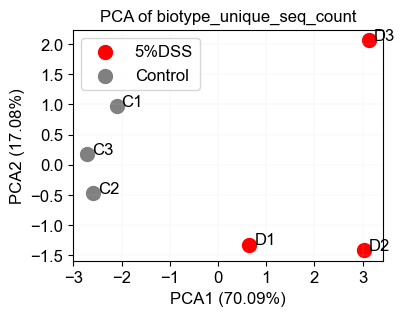

In [7]:
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")
base_path = "../../../../2nd_6samples_output"
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_gene_biotype_count.csv"), sep=",")
total = total_df.drop('gene_biotype', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**6).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)


X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))


pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)

pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']

plt.figure(figsize=(4, 3))
#1E90FF, #8B0000
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1']-0.1, subset['PC2'], label=group, color=colors[group], s=100)


for i, row in pca_df.iterrows():
    plt.text(row['PC1'], row['PC2'], row['Sample'],fontproperties=arial_font) 

plt.title('PCA of biotype_unique_seq_count',fontproperties=arial_font)
# plt.xlabel('PCA 1')
# plt.ylabel('PCA 2')
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)',fontproperties=arial_font)
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)',fontproperties=arial_font)
# Legend with Arial size 12
plt.legend(prop=arial_font)
# Axis tick labels with Arial size 12
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

# plt.grid(True)
plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("figure2_C.pdf", format="pdf", bbox_inches="tight")

In [3]:
import numpy as np
import pandas as pd
from os import listdir, path, makedirs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob


# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path):
    for name in names:
        file_path = os.path.join(base_path, name, "quantify_genome/output_unique_gene.csv")
        df = pd.read_csv(file_path, sep=',')
        df_dict[name] = df[df['gene'].notna()]

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='gene', how='left').fillna(0)
    result_df = result_df.rename(columns={'unique_seq_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['gene'] for name in names]).unique()
    result_df = pd.DataFrame({'gene': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)

# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
# read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


#df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total_with_match, base_path)


# filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_gene_count.csv")

DataFrame SRR18078869 has 1002 lines.
DataFrame SRR18078868 has 565 lines.
DataFrame SRR18078867 has 1545 lines.
DataFrame SRR18078872 has 1383 lines.
DataFrame SRR18078871 has 1407 lines.
DataFrame SRR18078870 has 1193 lines.
{'SRR18078869':        gene  unique_seq_count
0      aaeA                 1
1     abc-f                 4
2      accB                 1
3      accC                33
4      aceA                34
...     ...               ...
998    zapE                 4
999    zntB                10
1000   znuC                 3
1001   zupT                 1
1002    zwf                15

[1002 rows x 2 columns], 'SRR18078868':      gene  unique_seq_count
0     aat                 5
1    accB                 2
2    aceA                11
3    aceB                 1
4    aceE                18
..    ...               ...
561  yidC                 2
562  yjgA                 3
563  yqeK                 1
564  ytaF                 2
565  yycI                 2

[565 rows x 2 colum

aaa
         index   0     1    2     3     4     5     6    7     8  ...  2375  \
0  SRR18078869  31   124   31  1029  1061   249  1778  405   811  ...     0   
1  SRR18078868   0     0  106     0   586    53   959    0   159  ...     0   
2  SRR18078867   0     5   77    95   142   350   451   41   166  ...     0   
3  SRR18078872   0  1304  128  1385     0     0  1175   48   128  ...     0   
4  SRR18078871   0   742  204  1351    25     0  1927    6   352  ...     0   
5  SRR18078870   0   550  169   211   762  2963   550  254  1481  ...    42   

   2376  2377  2378  2379  2380  2381  2382  2383  2384  
0     0     0     0     0     0     0     0     0     0  
1     0     0     0     0     0     0     0     0     0  
2     0     0     0     0     0     0     0     0     0  
3     0     0     0     0     0     0     0     0     0  
4     0     0     0     0     0     0     0     0     0  
5    84    42    42    84    84  1735   338    42    42  

[6 rows x 2386 columns]
[[  31  124

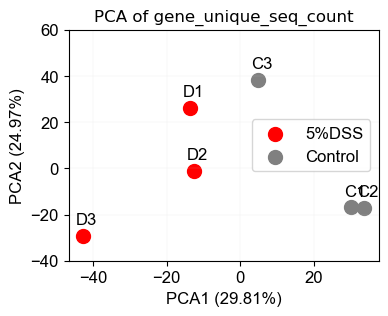

In [8]:

import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")
base_path = "../../../../2nd_6samples_output"
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_gene_count.csv"), sep=",")
total = total_df.drop('gene', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**6).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)


X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))



pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)

pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']

plt.figure(figsize=(4, 3))
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1'], subset['PC2'], label=group, color=colors[group], s=100)

for i, row in pca_df.iterrows():
    plt.text(row['PC1']-2, row['PC2']+5, row['Sample'],fontproperties=arial_font) 

plt.title('PCA of gene_unique_seq_count')
# plt.xlabel('PCA 1')
# plt.ylabel('PCA 2')
plt.ylim(-40,60)
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)',fontproperties=arial_font)
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)',fontproperties=arial_font)
# Legend with Arial size 12
plt.legend(prop=arial_font)
# Axis tick labels with Arial size 12
plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

# plt.grid(True)
plt.grid(True, color="lightgray", linewidth=0.1)

# plt.show()
plt.savefig("figure2_A.pdf", format="pdf", bbox_inches="tight")